# 04 · A synthetic patient cohort anchored to real NHS rates

**Why this notebook exists.** A discharge-planning risk score needs *patient-level* records:
length of stay, comorbidities, previous A&E visits. In England those live in Hospital Episode
Statistics (HES), which are only available through a formal NHS England application. Rather than
reuse a US dataset that thousands of portfolios already use, we build a transparent synthetic
cohort whose demographic structure comes from the real NHS file.

**What is real and what is assumed**

| Component | Source |
|---|---|
| Mix of discharges by year, deprivation quintile, age band and sex | **Real** NHS England denominators, 2022/23 to 2024/25 |
| Readmission rate in every year x deprivation x age x sex cell | **Real** NHS England rates (matched exactly) |
| Clinical features and their effects on risk | **Assumed**, loosely informed by the LACE literature |

Results from this cohort show **how** to build and validate a readmission model. They are not
evidence of how well such a model would perform on real NHS patients.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nhsread import viz
from nhsread.config import CELLS_FILE, COHORT_FILE
from nhsread.evaluation import metrics as M
from nhsread.synth.simulate import PROVIDER_SD, TRUE_EFFECTS, calibration_check, simulate_cohort

viz.set_style()
pd.set_option("display.width", 140)
cells = pd.read_parquet(CELLS_FILE)
cohort = simulate_cohort(cells)  # seeded: identical every run
cohort.to_parquet(COHORT_FILE, index=False)
print(f"{len(cohort):,} synthetic discharges ({cohort['year'].value_counts().sort_index().to_dict()})")
print(f"30-day readmission rate: {cohort['readmit_30d'].mean():.2%}")

240,000 synthetic discharges ({'2022/23': 76049, '2023/24': 81180, '2024/25': 82771})
30-day readmission rate: 14.68%


## 1. How the cohort is generated

1. **Sample discharges** in proportion to the real NHS denominators for every
   year x deprivation quintile x age band x sex cell.
2. **Draw clinical features** that depend on age and deprivation: older and more deprived
   patients have more comorbidity, longer stays, more prior A&E use.
3. **Generate the outcome** from a known logistic model:

$$\text{logit}\,p_i = \alpha_{\text{cell}(i)} + \sum_j \beta_j x_{ij} + u_{\text{hospital}(i)},
\qquad u \sim N(0, 0.15^2).$$

4. **Solve for each cell's intercept** $\alpha_{\text{cell}}$ (by root-finding) so that the mean
   risk in that cell equals the real NHS rate. The demographic pattern of risk is therefore real by
   construction; the clinical pattern is our assumption.

In [2]:
pd.Series(TRUE_EFFECTS, name="true log-odds effect").to_frame().assign(
    odds_ratio=lambda d: np.exp(d["true log-odds effect"])).round(3)

,true log-odds effect,odds_ratio
log_los,0.35,1.419
emergency,0.60,1.822
charlson_le4,0.30,1.350
charlson_gt4,0.10,1.105
charlson_x_under75,0.05,1.051
prior_ed_6m,0.17,1.185
log_prior_adm_12m,0.50,1.649
care_home,0.35,1.419
polypharmacy,0.25,1.284
medical_specialty,0.20,1.221


Two variables (`ward_occupancy`, `discharge_hour`) have **no** effect. They are there to test
whether variable selection correctly ignores them. Hospitals vary with a random effect
(sd = 0.15 on the log-odds scale) that the patient model does not see, as in reality.

## 2. Does the cohort reproduce the real NHS rates?

max |true mean risk - real NHS rate| across 45 year x deprivation x age groups: 0.00042
mean |simulated outcome rate - real rate|: 0.0049 (sampling noise from ~5,300 patients per group)


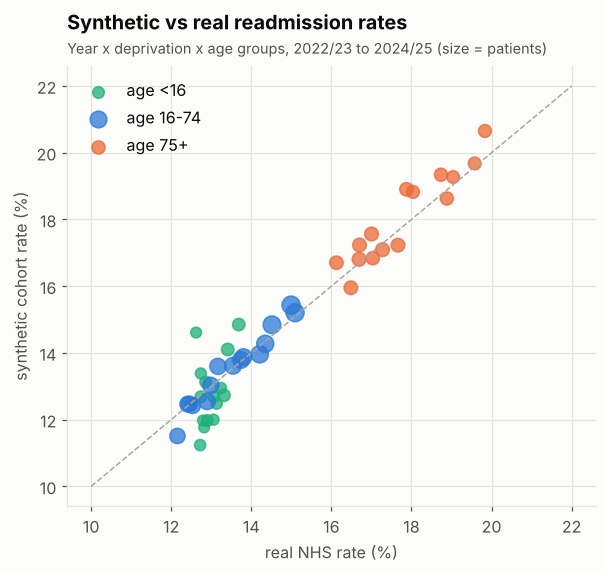

In [3]:
chk = calibration_check(cohort, cells)
print(f"max |true mean risk - real NHS rate| across {len(chk)} year x deprivation x age groups: {np.abs(chk['true_p'] - chk['real_rate']).max():.5f}")
print(f"mean |simulated outcome rate - real rate|: {np.abs(chk['sim_rate'] - chk['real_rate']).mean():.4f} "
      "(sampling noise from ~5,300 patients per group)")

fig, ax = plt.subplots(figsize=(6.2, 5.2))
for a, col in viz.AGE_COLOURS.items():
    s = chk[chk["age_band"] == a]
    ax.scatter(100 * s["real_rate"], 100 * s["sim_rate"], s=np.sqrt(s["n"]) * 1.2, color=col, alpha=0.75, label=f"age {a}")
ax.plot([10, 22], [10, 22], color=viz.GREY, ls="--", lw=1)
ax.set_xlabel("real NHS rate (%)")
ax.set_ylabel("synthetic cohort rate (%)")
ax.legend(loc="upper left")
ax.grid(True, axis="both")
ax.set_title("Synthetic vs real readmission rates")
viz.subtitle(ax, "Year x deprivation x age groups, 2022/23 to 2024/25 (size = patients)")
viz.save(fig, "04_calibration_to_real")
fig

## 3. What the patients look like

In [4]:
summary = cohort[["age", "los_days", "charlson", "prior_ed_6m", "prior_adm_12m"]].describe(percentiles=[0.5, 0.9, 0.99]).T
summary[["mean", "50%", "90%", "99%", "max"]].round(2)

,mean,50%,90%,99%,max
age,51.48,55.0,84.0,97.0,104.0
los_days,3.33,2.0,7.0,20.0,120.0
charlson,0.68,0.0,2.0,4.0,9.0
prior_ed_6m,0.71,0.0,2.0,5.0,16.0
prior_adm_12m,0.40,0.0,1.0,3.0,11.0


In [5]:
binary = cohort[["emergency", "care_home", "polypharmacy", "medical_specialty", "weekend_discharge"]].mean()
(100 * binary).round(1).to_frame("% of discharges")

,% of discharges
emergency,65.1
care_home,3.2
polypharmacy,11.4
medical_specialty,52.2
weekend_discharge,22.9


Skewed counts (length of stay, A&E visits, prior admissions) with long right tails are typical of
hospital data, and are a hint that raw linear terms will not be the best functional form.

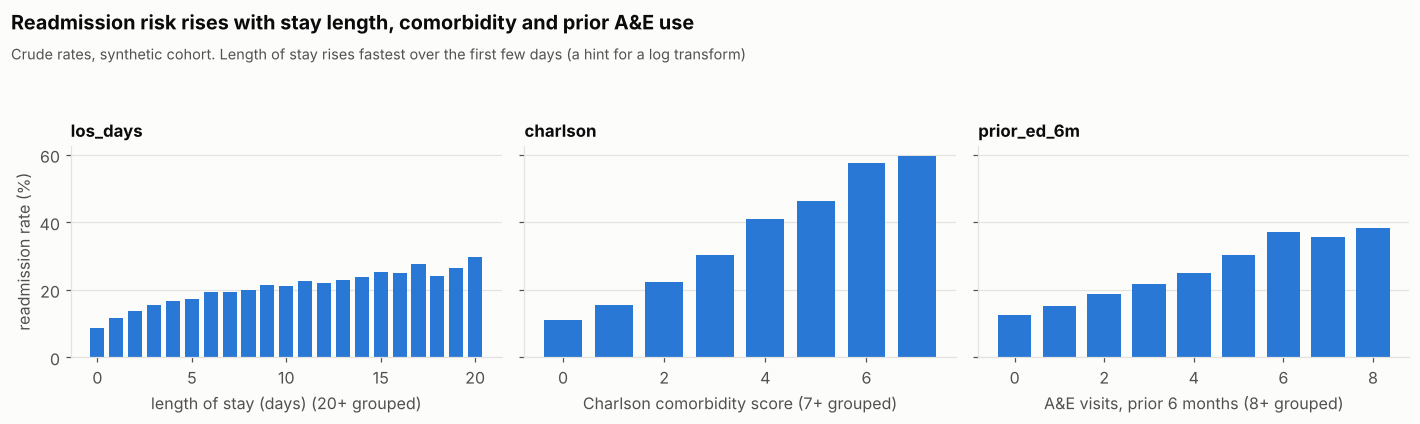

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, (col, label, cap) in zip(axes, [("los_days", "length of stay (days)", 20), ("charlson", "Charlson comorbidity score", 7),
                                        ("prior_ed_6m", "A&E visits, prior 6 months", 8)], strict=True):
    g = cohort.assign(x=cohort[col].clip(upper=cap)).groupby("x")["readmit_30d"].agg(["mean", "size"])
    ax.bar(g.index, 100 * g["mean"], color=viz.BLUE, width=0.75)
    ax.set_xlabel(label + f" ({cap}+ grouped)")
    ax.set_title(col, fontsize=11, pad=6)
axes[0].set_ylabel("readmission rate (%)")
viz.fig_title(fig, "Readmission risk rises with stay length, comorbidity and prior A&E use",
              "Crude rates, synthetic cohort. Length of stay rises fastest over the first few days (a hint for a log transform)")
viz.save(fig, "04_risk_by_feature")
fig

## 4. The ceiling: how predictable is readmission at all?

Because we know each patient's *true* probability, we can compute the best AUC any model could
achieve on these data. That ceiling is a useful reality check for later results.

In [7]:
oracle = M.auc(cohort["readmit_30d"], cohort["p_true"])
lace = M.lace_score(cohort["los_days"], cohort["emergency"], cohort["charlson"], cohort["prior_ed_6m"])
print(f"oracle AUC (true probabilities): {oracle:.3f}")
print(f"LACE index AUC:                  {M.auc(cohort['readmit_30d'], lace):.3f}")
print(f"hospital effect sd: {PROVIDER_SD} on the log-odds scale (unseen by the patient model)")

oracle AUC (true probabilities): 0.678
LACE index AUC:                  0.651
hospital effect sd: 0.15 on the log-odds scale (unseen by the patient model)


Even a perfect model only reaches an AUC of about 0.68. That is realistic: published UK and
international readmission scores typically report AUCs between 0.6 and 0.75, because much of what
drives a readmission (what happens after discharge, social support) is never in the hospital
record. A portfolio readmission model reporting an AUC of 0.95 should raise questions about
leakage, not admiration.

**Takeaways**

* 240,000 synthetic discharges whose demographic risk structure matches the real NHS data in every
  year x deprivation x age x sex cell (by construction; checked above at the 45-group level).
* Clinical effects are known, so notebook 05 can test whether the modelling recovers the truth.
* The best achievable AUC is about 0.68, which sets honest expectations for notebook 06.